# Counting rice grains: Cellpose vs area vs watershed

https://forum.image.sc/t/counting-rice-grains-in-a-smartphone-video-of-a-flat-silo-fiji-or-python/123120

Three counts of each image:
1. Cellpose with a small diameter (about one grain)
2. Otsu threshold, foreground area / area of one grain
3. Otsu threshold, distance transform, watershed, label

In [27]:
import os, glob, warnings
warnings.simplefilter('ignore', FutureWarning)
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from skimage.io import imread
from skimage.color import rgb2gray
from skimage.filters import threshold_otsu, gaussian
from skimage.morphology import remove_small_objects, opening, white_tophat, disk
from skimage.transform import rescale
from skimage.measure import regionprops, label
from skimage.segmentation import watershed
from skimage.feature import peak_local_max
from scipy import ndimage as ndi
from tnia.plotting.plt_helper import imshow_multi2d, random_label_cmap

In [28]:
parent_path = r'D:\images\tnia-python-images\imagesc\2026_11_10_rice_grains'
files = sorted(glob.glob(os.path.join(parent_path, '*.jpg')))
ims = [imread(f) for f in files]
for f, im in zip(files, ims):
    print(os.path.basename(f), im.shape)

20261031_101949.jpg (2560, 1920, 3)
20261031_111035.jpg (2560, 1920, 3)
20261031_111228.jpg (2560, 1920, 3)


Manual grain size, measured by eye in napari: 23 wide and 77 long.
Cellpose's diameter is the diameter of a circle of the same area, about sqrt(23 * 77) = 42.

In [29]:
grain_width, grain_length = 23, 77
diameter = 42
manual_grain_area = np.pi * (grain_width / 2) * (grain_length / 2)   # an ellipse
print('one grain, manual', round(manual_grain_area), 'px')

one grain, manual 1391 px


## 1. Cellpose

In [30]:
from cellpose import models
import cellpose
print('cellpose', cellpose.version)
model = models.CellposeModel(gpu=True)

cp_labels = [model.eval(im, diameter=diameter)[0] for im in ims]
cp_counts = [int(lab.max()) for lab in cp_labels]
cp_areas = np.concatenate([[r.area for r in regionprops(lab)] for lab in cp_labels])
print('cellpose counts', cp_counts, ' median grain area', np.median(cp_areas))

cellpose 4.0.8
cellpose counts [13, 41, 48]  median grain area 1397.5


### Keep Cellpose's grains, not the far away garbage

Cellpose also finds grain-like things far from the grains (the cloth at the bottom of the first image).
The threshold mask finds the grains, and its bounding box (plus a margin) is the region of interest:
Cellpose objects whose centre is outside it are dropped.

The threshold: Otsu on the raw image splits the dark board from the grey board and glare, not grains from board.
So first subtract the background: a white top-hat with a disk bigger than a grain keeps only the
small bright things. (Done at 1/4 size, as a top-hat of that radius is slow at full size.)

In [31]:
def grain_mask(im):
    g = gaussian(rgb2gray(im[..., :3]), sigma=2)
    small = rescale(g, 0.25, anti_aliasing=True)
    background = small - white_tophat(small, disk(grain_length // 4))
    background = rescale(background, 4, order=1)[:g.shape[0], :g.shape[1]]
    grains = g - background
    fg = grains > threshold_otsu(grains)
    fg = opening(fg, disk(3))
    return remove_small_objects(fg, max_size=int(manual_grain_area / 6))

def roi_only(lab, fg, pad=grain_length):
    ys, xs = np.nonzero(fg)
    y0, y1, x0, x1 = ys.min() - pad, ys.max() + pad, xs.min() - pad, xs.max() + pad
    keep = [r.label for r in regionprops(lab) if y0 <= r.centroid[0] <= y1 and x0 <= r.centroid[1] <= x1]
    return label(np.where(np.isin(lab, keep), lab, 0))

masks = [grain_mask(im) for im in ims]
before = cp_counts
cp_labels = [roi_only(lab, m) for lab, m in zip(cp_labels, masks)]
cp_counts = [int(lab.max()) for lab in cp_labels]
cp_areas = np.concatenate([[r.area for r in regionprops(lab)] for lab in cp_labels])
print('cellpose counts', before, '-> in the ROI', cp_counts, ' median grain area', np.median(cp_areas))

cellpose counts [13, 41, 48] -> in the ROI [10, 40, 40]  median grain area 1415.0


## 2. Threshold, area / one grain

The same threshold masks, made above.

In [32]:
manual_counts = [m.sum() / manual_grain_area for m in masks]

## 3. Threshold, watershed, label

A long grain has a ridge, not one peak, in its distance map, which splits it in two.
Smoothing the distance map and keeping peaks 3/4 of a grain width apart gives one seed per grain.

In [33]:
def watershed_labels(fg):
    dist = ndi.gaussian_filter(ndi.distance_transform_edt(fg), 3)
    peaks = peak_local_max(dist, min_distance=grain_width * 3 // 4,
                           labels=label(fg), exclude_border=False)
    markers = np.zeros(dist.shape, dtype=np.int32)
    markers[tuple(peaks.T)] = np.arange(1, len(peaks) + 1)
    return watershed(-dist, markers, mask=fg)

ws_labels = [watershed_labels(m) for m in masks]
ws_counts = [len(np.unique(lab)) - 1 for lab in ws_labels]
print('watershed counts', ws_counts)

watershed counts [10, 41, 27]


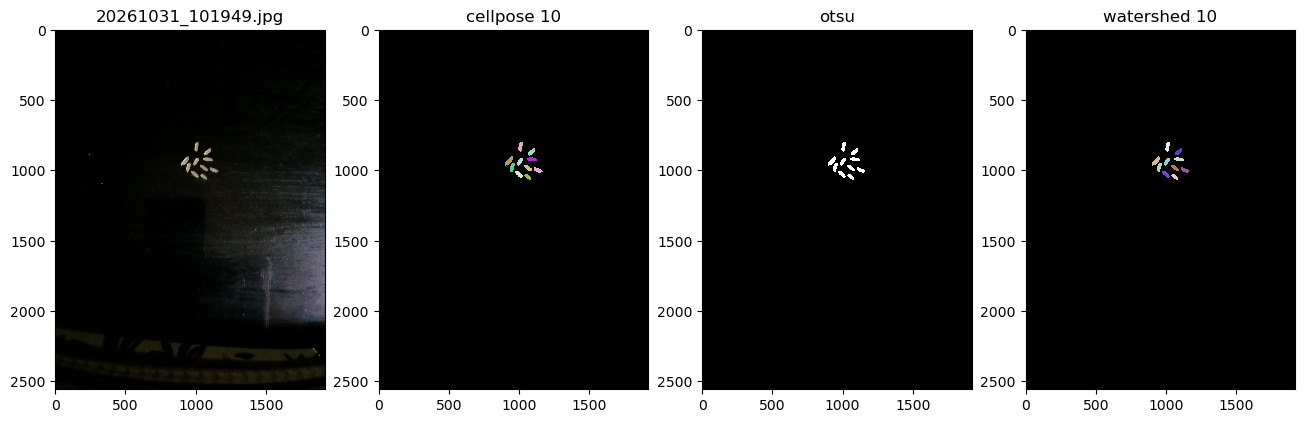

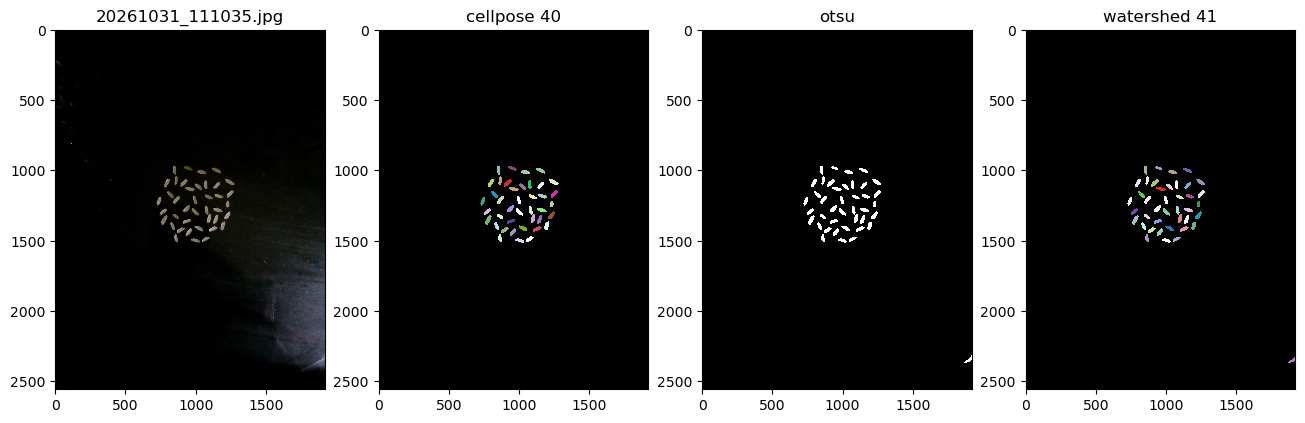

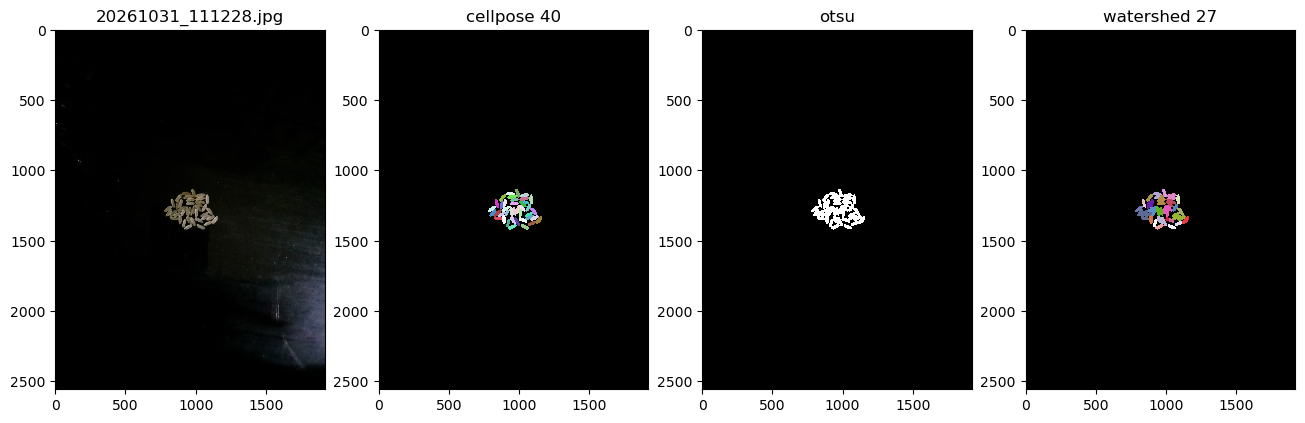

In [36]:
for i, f in enumerate(files):
    found = masks[i] | (cp_labels[i] > 0) | (ws_labels[i] > 0)
    imshow_multi2d([ims[i], cp_labels[i], masks[i], ws_labels[i]],
                   [os.path.basename(f), f'cellpose {cp_counts[i]}', 'otsu', f'watershed {ws_counts[i]}'], 1, 4,
                   colormaps=['gray', random_label_cmap(), 'gray', random_label_cmap()], width=16, height=5)

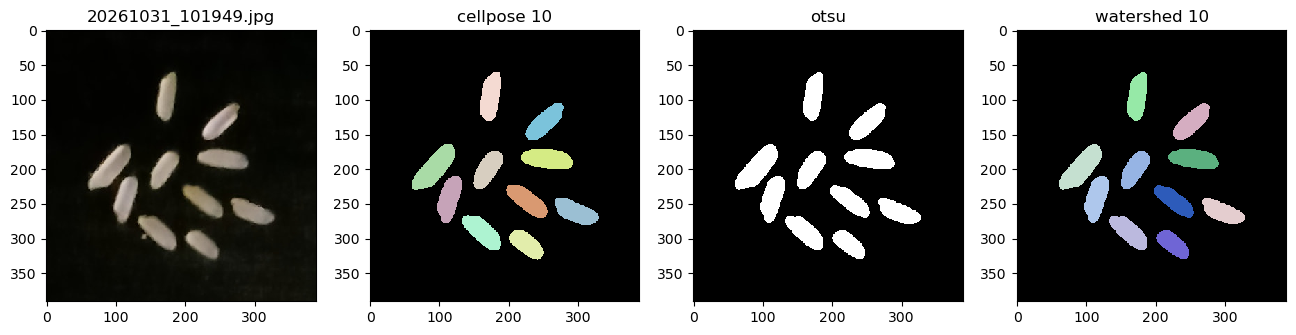

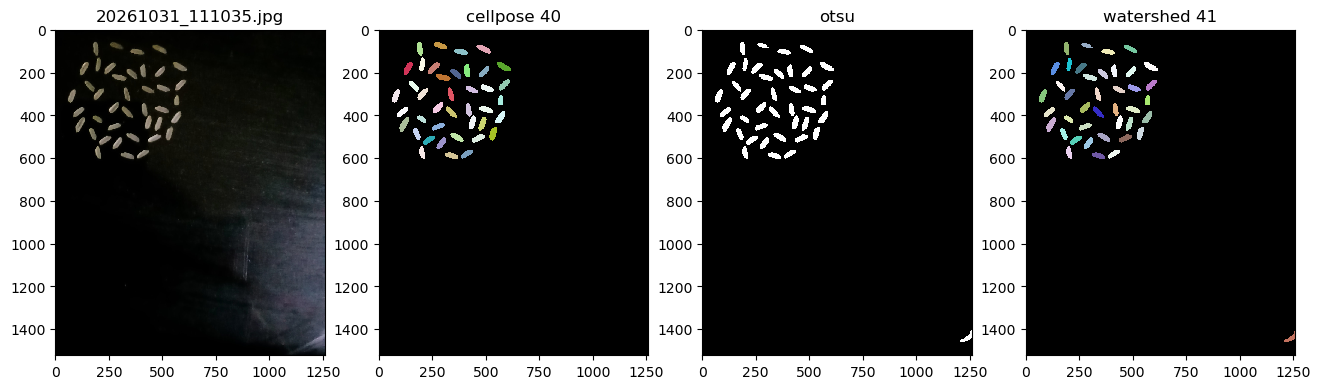

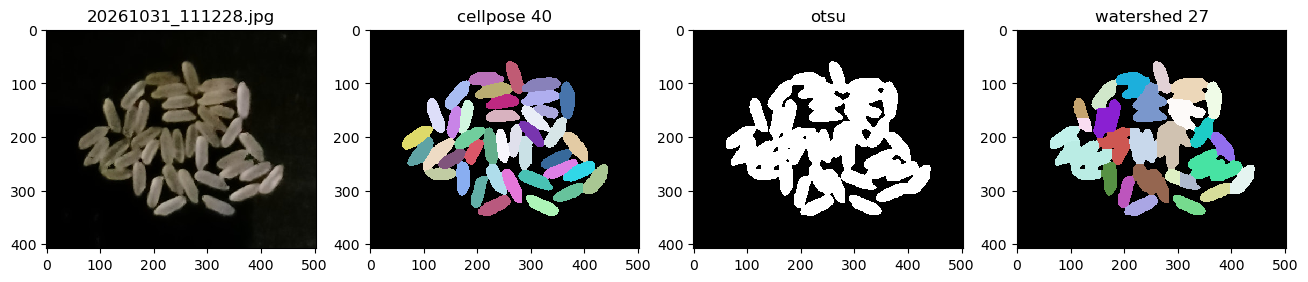

In [34]:
def crop(a, found):
    # everything any method found, with a margin
    ys, xs = np.nonzero(found)
    pad = 60
    return a[max(ys.min() - pad, 0):ys.max() + pad, max(xs.min() - pad, 0):xs.max() + pad]

for i, f in enumerate(files):
    found = masks[i] | (cp_labels[i] > 0) | (ws_labels[i] > 0)
    imshow_multi2d([crop(ims[i], found), crop(cp_labels[i], found), crop(masks[i], found), crop(ws_labels[i], found)],
                   [os.path.basename(f), f'cellpose {cp_counts[i]}', 'otsu', f'watershed {ws_counts[i]}'], 1, 4,
                   colormaps=['gray', random_label_cmap(), 'gray', random_label_cmap()], width=16, height=5)

## Do they agree?

In [35]:
print(f'manual grain size estimated as {grain_width} x {grain_length} px, '
      f'an ellipse of {manual_grain_area:.0f} px')
table = pd.DataFrame({
    'image': [os.path.basename(f) for f in files],
    'cellpose count': cp_counts,
    'area / manual grain size': np.round(manual_counts, 1),
    'watershed count': ws_counts,
    'cellpose mean grain size': [round(np.mean([r.area for r in regionprops(lab)])) for lab in cp_labels],
})
table

manual grain size estimated as 23 x 77 px, an ellipse of 1391 px


,image,cellpose count,area / manual grain size,watershed count,cellpose mean grain size
0,20261031_101949.jpg,10,11.0,10,1623
1,20261031_111035.jpg,40,39.6,41,1443
2,20261031_111228.jpg,40,38.5,27,1320


In [ ]:
import napari
viewer = napari.Viewer()
i = 2   # the clump
viewer.add_image(ims[i], name='image')
viewer.add_labels(cp_labels[i], name='cellpose')
viewer.add_labels(ws_labels[i], name='watershed')